# Bài 5: Cây quyết định và Rừng ngẫu nhiên - 6 bài tập

**Môn học:** Học máy và ứng dụng  
**Họ tên:** Huỳnh Hữu Phúc  
**MSSV:** 2474802010314  
**Dữ liệu:** `data/khach_vay.csv`, `data/gia_nha.csv`

Giải đủ sáu bài ở mục 9 của PDF (trang PDF 22–23), theo cấu trúc Lab 3.
Mỗi lời giải kế thừa đoạn mẫu tương ứng và bổ sung đúng phần đề yêu cầu.
Các bài tập không có lời giải mẫu sẵn trong PDF. Mỗi cell bài tập tự đọc dữ liệu và
tạo mô hình để tránh phụ thuộc biến của notebook thực hành.

Mỗi mục gồm yêu cầu, mã chạy, kết quả và nhận xét. Chọn kernel có các thư viện trong
`requirements.txt`, sau đó **Restart Kernel and Run All**. Cell chuẩn bị chỉ xử lý đường dẫn,
cho phép mở notebook từ thư mục `code/` hoặc thư mục gốc của bài làm.


## Chuẩn bị thư mục làm việc

In [1]:
# Chỉ thiết lập thư mục chạy; các đoạn code mẫu bên dưới giữ nguyên.
from pathlib import Path
import os

if not Path("data/khach_vay.csv").is_file() and Path("../data/khach_vay.csv").is_file():
    os.chdir("..")
if not all(Path("data", ten).is_file() for ten in ["khach_vay.csv", "gia_nha.csv"]):
    raise FileNotFoundError("Mở notebook từ code/ hoặc thư mục 05. CayQuyetDinh_RungNgauNhien.")
Path("figures").mkdir(exist_ok=True)


## Bài tập 1. Tự vẽ cây

**Yêu cầu:** Vẽ và lưu `figures/cay_nam_la.png`; vẽ cây `max_depth=2`. Xác định hai lá bên trái có cùng kết luận không và giải thích vì sao vẫn chia.

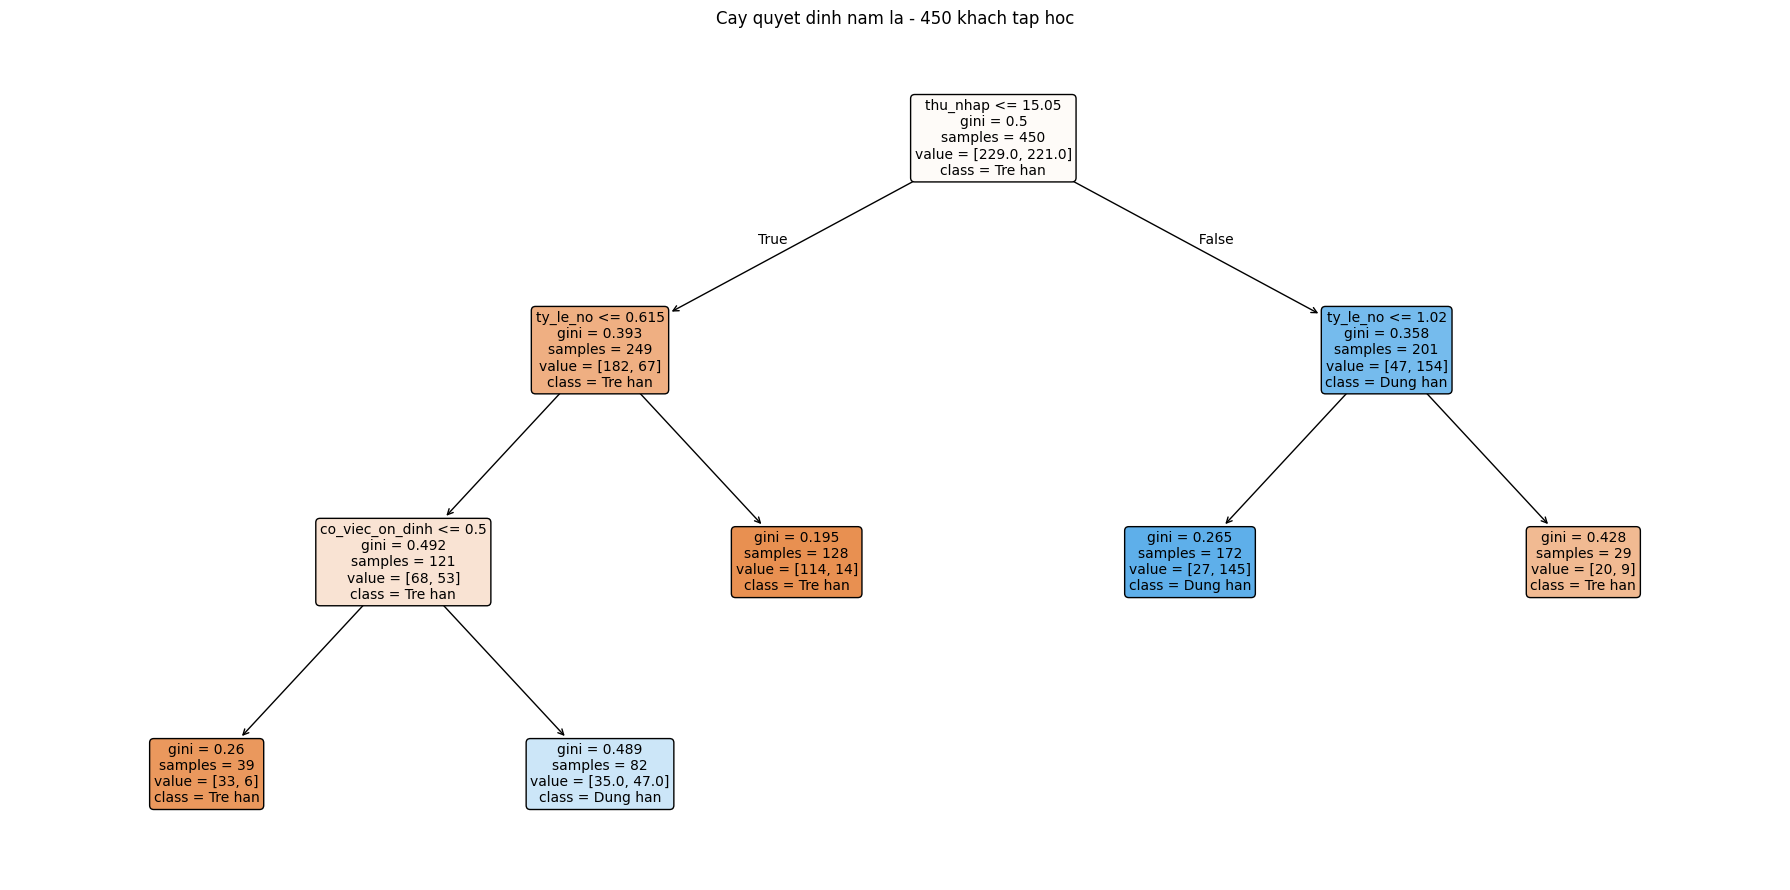

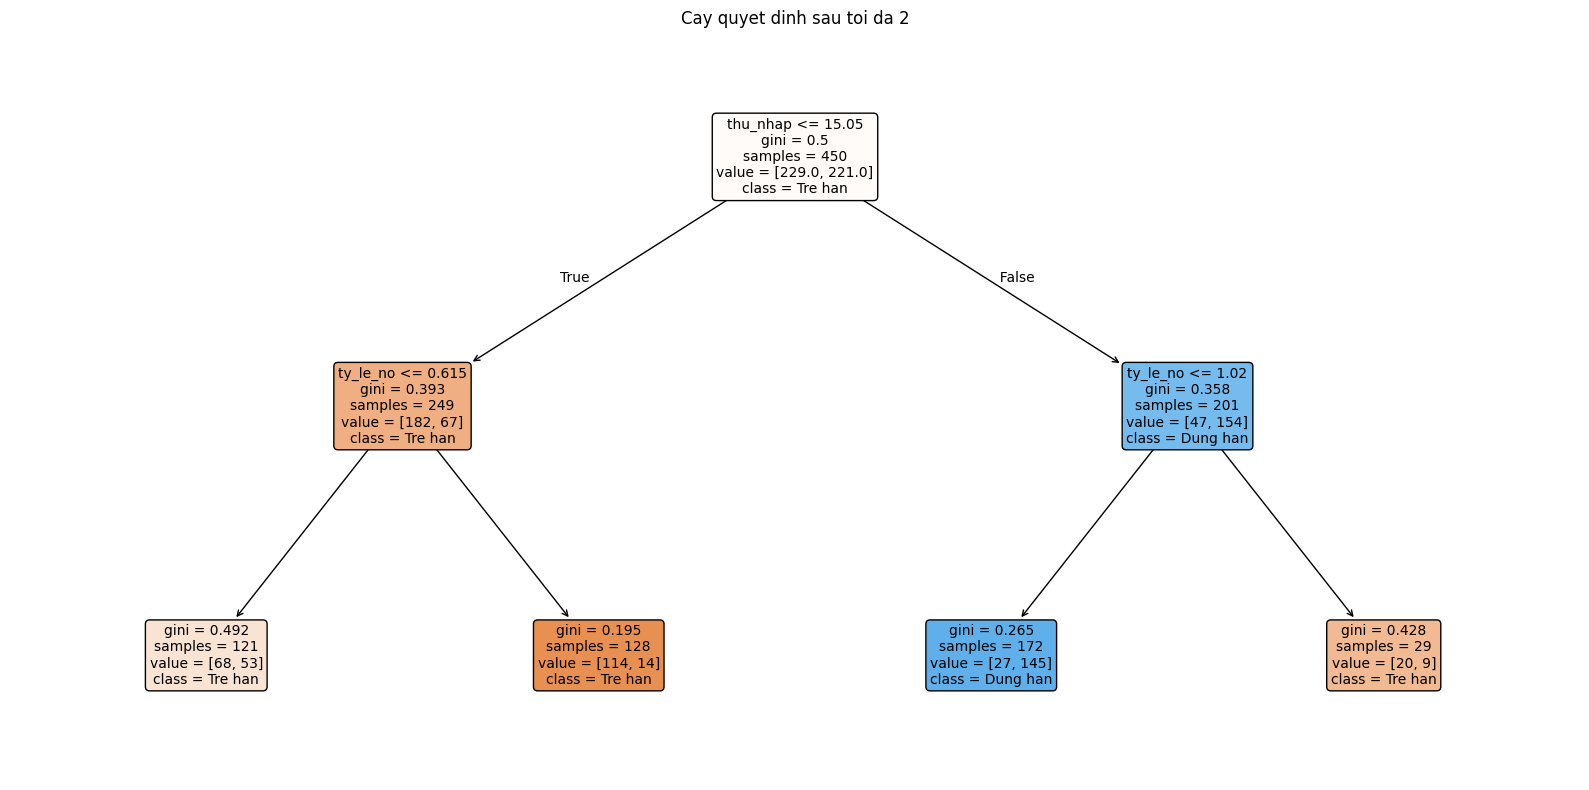

|--- thu_nhap <= 15.050
|   |--- ty_le_no <= 0.615
|   |   |--- weights: [68.000, 53.000] class: 0
|   |--- ty_le_no >  0.615
|   |   |--- weights: [114.000, 14.000] class: 0
|--- thu_nhap >  15.050
|   |--- ty_le_no <= 1.020
|   |   |--- weights: [27.000, 145.000] class: 1
|   |--- ty_le_no >  1.020
|   |   |--- weights: [20.000, 9.000] class: 0

Hai la ben trai:
  Nut 2: samples=121, Gini=0.4923, class=0
  Nut 3: samples=128, Gini=0.1948, class=0
Gini truoc chia: 0.3933; sau chia: 0.3394; giam: 0.0540
Da luu figures/cay_nam_la.png va figures/cay_sau_2.png


In [2]:
"""Bài 1: mở rộng f2_cay_nam_la.py để vẽ cây và đọc hai lá bên trái."""
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, export_text, plot_tree

df = pd.read_csv("data/khach_vay.csv")
X = df.drop(columns="tra_dung_han")
y = df["tra_dung_han"]
X_tr, X_te, y_tr, y_te = train_test_split(
    X, y, test_size=0.25, random_state=17, stratify=y
)
cay = DecisionTreeClassifier(max_leaf_nodes=5, random_state=0).fit(X_tr, y_tr)
plt.figure(figsize=(18, 9))
plot_tree(cay, feature_names=list(X.columns), class_names=["Tre han", "Dung han"],
          filled=True, rounded=True, precision=3, fontsize=10)
plt.title("Cay quyet dinh nam la - 450 khach tap hoc")
plt.tight_layout()
plt.savefig("figures/cay_nam_la.png", dpi=180, bbox_inches="tight")
plt.show()

cay2 = DecisionTreeClassifier(max_depth=2, random_state=0).fit(X_tr, y_tr)
plt.figure(figsize=(16, 8))
plot_tree(cay2, feature_names=list(X.columns), class_names=["Tre han", "Dung han"],
          filled=True, rounded=True, precision=3, fontsize=10)
plt.title("Cay quyet dinh sau toi da 2")
plt.tight_layout()
plt.savefig("figures/cay_sau_2.png", dpi=180, bbox_inches="tight")
plt.show()
print(export_text(cay2, feature_names=list(X.columns), show_weights=True, decimals=3))

# Đọc nút con trái của gốc và hai lá con của nó.
t = cay2.tree_
nut_trai = t.children_left[0]
hai_la = [t.children_left[nut_trai], t.children_right[nut_trai]]
print("Hai la ben trai:")
for la in hai_la:
    nhan = cay2.classes_[np.argmax(t.value[la][0])]
    print(f"  Nut {la}: samples={t.n_node_samples[la]}, Gini={t.impurity[la]:.4f}, class={nhan}")
gini_truoc = t.impurity[nut_trai]
gini_sau = sum(t.n_node_samples[la] * t.impurity[la] for la in hai_la) / t.n_node_samples[nut_trai]
print(f"Gini truoc chia: {gini_truoc:.4f}; sau chia: {gini_sau:.4f}; giam: {gini_truoc-gini_sau:.4f}")
print("Da luu figures/cay_nam_la.png va figures/cay_sau_2.png")


**Nhận xét:**

Đã vẽ cây năm lá và cây sâu 2, lưu tại `figures/cay_nam_la.png` và
`figures/cay_sau_2.png`, đồng thời nhúng cả hai hình ngay trong notebook.

Hai lá bên trái của cây sâu 2 **đều dự đoán lớp 0 (trễ hạn)**, nhưng phân bố khác nhau:
lá `[68, 53]` có Gini **0,4923**, lá `[114, 14]` có Gini **0,1948**.
Trước khi chia, nút trái có Gini **0,3933**; sau chia, Gini có trọng số còn **0,3394**,
giảm khoảng **0,0540**. Cây tối ưu mức giảm độ hỗn tạp, không đòi nhãn đa số
ở hai nhánh phải khác nhau. Phép chia vẫn có ích vì làm rõ hai nhóm có xác suất
đúng hạn khác nhau và có thể tạo điều kiện chia tiếp nếu cho phép sâu hơn.

## Bài tập 2. Tự tìm câu hỏi gốc trên dữ liệu thật

**Yêu cầu:** Viết `tim_cau_hoi(X, y)` bằng cách thử mọi cột, mọi trung điểm; chỉ dùng 450 khách train. Đối chiếu câu hỏi gốc thu nhập ≤ 15,05 với scikit-learn.

In [3]:
"""Bài 2: mở rộng cách thử ngưỡng và tính Gini trong f1_gini.py."""
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier

def gini(nhan):
    """Chỉ số Gini của nút hai lớp, giống Bước 1."""
    if len(nhan) == 0:
        return 0.0
    p1 = np.asarray(nhan).mean()
    return 1 - p1 ** 2 - (1 - p1) ** 2

def tim_cau_hoi(X, y):
    """Thử mọi cột và trung điểm giữa hai giá trị phân biệt kề nhau.

    Trả về cột và ngưỡng có Gini giảm lớn nhất. Nếu hoà, giữ câu hỏi
    gặp trước theo thứ tự cột và ngưỡng tăng dần.
    """
    nhan = np.asarray(y)
    g_goc = gini(nhan)
    giam_tot = -np.inf
    cot_tot, nguong_tot = None, None
    for cot in X.columns:
        gia_tri = X[cot].to_numpy()
        muc = np.sort(np.unique(gia_tri))
        for a, b in zip(muc[:-1], muc[1:]):
            nguong = (a + b) / 2
            di_trai = gia_tri <= nguong
            trai, phai = nhan[di_trai], nhan[~di_trai]
            g_sau = (len(trai) * gini(trai) + len(phai) * gini(phai)) / len(nhan)
            giam = g_goc - g_sau
            if giam > giam_tot:
                cot_tot, nguong_tot, giam_tot = cot, nguong, giam
    if cot_tot is None:
        raise ValueError("Không có cột nào có ít nhất hai giá trị khác nhau.")
    return cot_tot, nguong_tot

df = pd.read_csv("data/khach_vay.csv")
X = df.drop(columns="tra_dung_han")
y = df["tra_dung_han"]
X_tr, X_te, y_tr, y_te = train_test_split(
    X, y, test_size=0.25, random_state=17, stratify=y
)
cot, nguong = tim_cau_hoi(X_tr, y_tr)
di_trai = X_tr[cot].to_numpy() <= nguong
nhan = y_tr.to_numpy()
g_goc = gini(nhan)
g_sau = (di_trai.sum() * gini(nhan[di_trai]) + (~di_trai).sum() * gini(nhan[~di_trai])) / len(nhan)
print(f"So mau train: {len(X_tr)}; so mau test giu rieng: {len(X_te)}")
print(f"Tu tinh: {cot} <= {nguong:.5f}")
print(f"Gini goc: {g_goc:.6f}; sau chia: {g_sau:.6f}; giam: {g_goc-g_sau:.6f}")
print(f"Hai nhanh co {di_trai.sum()} va {(~di_trai).sum()} khach")
cay = DecisionTreeClassifier(max_depth=1, random_state=0).fit(X_tr, y_tr)
cot_sklearn = X.columns[cay.tree_.feature[0]]
nguong_sklearn = cay.tree_.threshold[0]
print(f"scikit-learn: {cot_sklearn} <= {nguong_sklearn:.5f}")
print("Trung ket qua:", cot == cot_sklearn and np.isclose(nguong, nguong_sklearn))


So mau train: 450; so mau test giu rieng: 150
Tu tinh: thu_nhap <= 15.05000
Gini goc: 0.499842; sau chia: 0.377697; giam: 0.122145
Hai nhanh co 249 va 201 khach
scikit-learn: thu_nhap <= 15.05000
Trung ket qua: True


**Nhận xét:**

Trên đúng **450** khách train, hàm chọn **`thu_nhap <= 15.05`**, trùng
`DecisionTreeClassifier(max_depth=1, random_state=0)`.
Gini gốc **0,499842**, sau chia **0,377697**, giảm **0,122145**;
hai nhánh có **249** và **201** khách.

Với mỗi cột, chỉ cần thử trung điểm của hai giá trị phân biệt kề nhau: các ngưỡng
nằm trong cùng khoảng tạo cùng cách chia. Tính Gini hai nhánh rồi lấy trung bình
**có trọng số theo số khách**; chọn mức giảm lớn nhất trên tất cả cột và ngưỡng.
Không dùng test hoặc nhãn test để tìm câu hỏi. Hàm dùng mảng nhãn cùng thứ tự dòng
với X để tránh nhầm chỉ số sau train_test_split.

Ngưỡng trong cây scikit-learn có thể lệch rất nhỏ do biểu diễn float32, nên đối chiếu
bằng `np.isclose`. Kết quả 15,05 áp dụng cho cây CART Gini trên cùng train, cùng
tập cột và các thiết lập phù hợp; cây con của rừng dùng bootstrap và lấy cột ngẫu nhiên
không bắt buộc có cùng câu hỏi gốc. Cách nói “mọi cây” trong đề cần hiểu theo phạm vi này.

## Bài tập 3. Gini hay entropy

**Yêu cầu:** Chạy lại quá trình chọn độ sâu 1–15 bằng CV 5 phần với `criterion="entropy"`; so độ sâu tốt nhất và accuracy test với Gini. Nếu điểm CV hoà, chọn độ sâu xuất hiện trước, giống mẫu.

In [4]:
"""Bài 3: chạy lại f3_do_sau.py cho Gini và entropy, cùng cách chia/CV."""
import pandas as pd
from sklearn.metrics import accuracy_score
from sklearn.model_selection import cross_val_score, train_test_split
from sklearn.tree import DecisionTreeClassifier

df = pd.read_csv("data/khach_vay.csv")
X = df.drop(columns="tra_dung_han")
y = df["tra_dung_han"]
X_tr, X_te, y_tr, y_te = train_test_split(
    X, y, test_size=0.25, random_state=17, stratify=y
)
ket_qua = []
for tieu_chi in ["gini", "entropy"]:
    print(f"\nTieu chi: {tieu_chi}")
    tu_do = DecisionTreeClassifier(criterion=tieu_chi, random_state=0).fit(X_tr, y_tr)
    print(f"Cay tu do: do sau={tu_do.get_depth()}, so la={tu_do.get_n_leaves()}, "
          f"train={accuracy_score(y_tr, tu_do.predict(X_tr)):.4f}, "
          f"test={accuracy_score(y_te, tu_do.predict(X_te)):.4f}")
    print("Do sau   tap hoc   kiem dinh cheo")
    diem = {}
    for d in range(1, 16):
        mh = DecisionTreeClassifier(criterion=tieu_chi, max_depth=d, random_state=0)
        diem[d] = cross_val_score(mh, X_tr, y_tr, cv=5).mean()
        hoc = accuracy_score(y_tr, mh.fit(X_tr, y_tr).predict(X_tr))
        print(f"{d:6d}   {hoc:.4f}    {diem[d]:.4f}")
    d_tot = max(diem, key=diem.get)
    tot = DecisionTreeClassifier(criterion=tieu_chi, max_depth=d_tot, random_state=0)
    tot.fit(X_tr, y_tr)
    acc = accuracy_score(y_te, tot.predict(X_te))
    ket_qua.append({"criterion": tieu_chi, "max_depth": d_tot,
                    "CV": diem[d_tot], "so_la": tot.get_n_leaves(), "test_accuracy": acc})
print("\nSo sanh sau khi chon do sau bang CV:")
print(pd.DataFrame(ket_qua).to_string(index=False, float_format=lambda x: f"{x:.4f}"))



Tieu chi: gini
Cay tu do: do sau=13, so la=92, train=1.0000, test=0.7667
Do sau   tap hoc   kiem dinh cheo
     1   0.7467    0.7244
     2   0.7711    0.7378
     3   0.8000    0.7511
     4   0.8644    0.8089
     5   0.8978    0.8333
     6   0.9133    0.8156
     7   0.9400    0.8067
     8   0.9600    0.7733
     9   0.9800    0.7800
    10   0.9911    0.7822


    11   0.9933    0.7756


    12   0.9978    0.7778
    13   1.0000    0.7733
    14   1.0000    0.7733
    15   1.0000    0.7733

Tieu chi: entropy
Cay tu do: do sau=13, so la=88, train=1.0000, test=0.7667
Do sau   tap hoc   kiem dinh cheo
     1   0.7467    0.7244
     2   0.7711    0.7133
     3   0.7733    0.7489
     4   0.8511    0.8111
     5   0.8956    0.8222
     6   0.9111    0.8222


     7   0.9378    0.8089
     8   0.9533    0.7933


     9   0.9778    0.7844
    10   0.9867    0.7978
    11   0.9933    0.7911
    12   0.9978    0.7822
    13   1.0000    0.7822
    14   1.0000    0.7822
    15   1.0000    0.7867

So sanh sau khi chon do sau bang CV:
criterion  max_depth     CV  so_la  test_accuracy
     gini          5 0.8333     27         0.8533
  entropy          5 0.8222     23         0.8467


**Nhận xét:**

Gini chọn độ sâu **5**, CV **0,8333**, 27 lá, test **0,8533**.
Entropy cũng chọn độ sâu **5**, CV **0,8222**, 23 lá, test **0,8467**.
Hai độ sâu 5 và 6 của entropy có điểm in ra cùng **0,8222**; vòng lặp và `max`
giữ cấu hình đạt cực đại xuất hiện trước khi bằng điểm.

**Đổi thước đo chỉ làm accuracy test giảm khoảng 0,0067 (0,67 điểm phần trăm,
tương ứng 1/150 mẫu), nên không tạo khác biệt lớn trên lần chia dữ liệu này.**
Điều đó không khẳng định Gini luôn tốt hơn entropy trên dữ liệu khác.

## Bài tập 4. Cắt tỉa bằng số khách tối thiểu ở lá

**Yêu cầu:** Không giới hạn độ sâu. Thử `min_samples_leaf` = 1, 2, 5, 10, 20, 40; chọn bằng CV 5 phần trên train, chấm cấu hình đã chọn một lần trên test, so với cây sâu 5.

In [5]:
"""Bài 4: thay vòng lặp độ sâu của f3_do_sau.py bằng min_samples_leaf."""
import pandas as pd
from sklearn.metrics import accuracy_score
from sklearn.model_selection import cross_val_score, train_test_split
from sklearn.tree import DecisionTreeClassifier

df = pd.read_csv("data/khach_vay.csv")
X = df.drop(columns="tra_dung_han")
y = df["tra_dung_han"]
X_tr, X_te, y_tr, y_te = train_test_split(
    X, y, test_size=0.25, random_state=17, stratify=y
)
diem = {}
print("min_samples_leaf   tap hoc   kiem dinh cheo")
for n_la in [1, 2, 5, 10, 20, 40]:
    mh = DecisionTreeClassifier(min_samples_leaf=n_la, random_state=0)
    diem[n_la] = cross_val_score(mh, X_tr, y_tr, cv=5).mean()
    hoc = accuracy_score(y_tr, mh.fit(X_tr, y_tr).predict(X_tr))
    print(f"{n_la:16d}   {hoc:.4f}    {diem[n_la]:.4f}")
n_tot = max(diem, key=diem.get)
tot = DecisionTreeClassifier(min_samples_leaf=n_tot, random_state=0).fit(X_tr, y_tr)
acc_la = accuracy_score(y_te, tot.predict(X_te))
cay5 = DecisionTreeClassifier(max_depth=5, random_state=0).fit(X_tr, y_tr)
acc_sau = accuracy_score(y_te, cay5.predict(X_te))
print(f"\nChon min_samples_leaf={n_tot} bang CV={diem[n_tot]:.4f}")
print(f"Cay chon: do sau={tot.get_depth()}, so la={tot.get_n_leaves()}, test={acc_la:.4f}")
print(f"Cay max_depth=5: do sau={cay5.get_depth()}, so la={cay5.get_n_leaves()}, test={acc_sau:.4f}")
print(f"Chenh accuracy (min_samples_leaf - max_depth): {acc_la-acc_sau:+.4f}")


min_samples_leaf   tap hoc   kiem dinh cheo
               1   1.0000    0.7733
               2   0.9467    0.7822


               5   0.8956    0.8067
              10   0.8600    0.8089


              20   0.8422    0.8089
              40   0.7822    0.7133

Chon min_samples_leaf=10 bang CV=0.8089
Cay chon: do sau=8, so la=30, test=0.8467
Cay max_depth=5: do sau=5, so la=27, test=0.8533
Chenh accuracy (min_samples_leaf - max_depth): -0.0067


**Nhận xét:**

Các điểm CV theo `min_samples_leaf` = 1, 2, 5, 10, 20, 40 lần lượt là
**0,7733 / 0,7822 / 0,8067 / 0,8089 / 0,8089 / 0,7133**.
Code chọn **10**; khi bằng điểm giữ giá trị xuất hiện trước. Cây có **30 lá**, sâu **8**,
test **0,8467**. Cây `max_depth=5` có **27 lá**, test **0,8533**,
cao hơn khoảng **0,0067**, tức 1 dự đoán đúng trên 150 mẫu test.

Với lần chia này, giới hạn độ sâu 5 cho kết quả tốt hơn một chút. Hai cách cắt tỉa
kiểm soát độ phức tạp khác nhau: giới hạn độ sâu chặn số câu hỏi trên đường đi;
giới hạn số mẫu tại lá ngăn các lá quá ít dữ liệu. Test chỉ dùng để chấm cấu hình
đã chọn bằng CV và so sánh với mốc cố định, không chọn từ sáu giá trị theo test.

## Bài tập 5. Độ quan trọng bằng cách xáo trộn

**Yêu cầu:** Dùng lại đúng rừng và cột ngẫu nhiên của Bước 6. Thêm cột ngẫu nhiên tương tự cho test; dùng `n_repeats=20`, `random_state=0`. So thứ hạng, giải thích MDI và permutation.

In [6]:
"""Bài 5: mở rộng f6_do_quan_trong.py, so MDI với permutation trên test."""
import numpy as np
import pandas as pd
from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import accuracy_score
from sklearn.model_selection import train_test_split

df = pd.read_csv("data/khach_vay.csv")
X = df.drop(columns="tra_dung_han")
y = df["tra_dung_han"]
X_tr, X_te, y_tr, y_te = train_test_split(
    X, y, test_size=0.25, random_state=17, stratify=y
)
# Giữ đúng cột train của Bước 6; tiếp tục cùng RNG để tạo cột test độc lập.
rng = np.random.default_rng(0)
X_tr_nn, X_te_nn = X_tr.copy(), X_te.copy()
X_tr_nn["so_ngau_nhien"] = rng.random(len(X_tr))
X_te_nn["so_ngau_nhien"] = rng.random(len(X_te))
rung_nn = RandomForestClassifier(n_estimators=200, random_state=0).fit(X_tr_nn, y_tr)
qt_nn = pd.Series(rung_nn.feature_importances_, index=X_tr_nn.columns)
hoan_vi = permutation_importance(rung_nn, X_te_nn, y_te,
                                n_repeats=20, random_state=0, scoring="accuracy")
bang = pd.DataFrame({"MDI": qt_nn,
                     "permutation_mean": hoan_vi.importances_mean,
                     "permutation_std": hoan_vi.importances_std})
bang["hang_MDI"] = bang["MDI"].rank(ascending=False, method="min").astype(int)
bang["hang_permutation"] = bang["permutation_mean"].rank(ascending=False, method="min").astype(int)
print(f"Accuracy test cua rung co cot ngau nhien: {accuracy_score(y_te, rung_nn.predict(X_te_nn)):.4f}")
print("Do quan trong giam dan theo permutation (don vi: muc giam accuracy):")
print(bang.sort_values("permutation_mean", ascending=False).to_string(float_format=lambda x: f"{x:.4f}"))
print(f"Cot ngau nhien: hang MDI={bang.loc['so_ngau_nhien', 'hang_MDI']}, "
      f"hang permutation={bang.loc['so_ngau_nhien', 'hang_permutation']}")


Accuracy test cua rung co cot ngau nhien: 0.9067
Do quan trong giam dan theo permutation (don vi: muc giam accuracy):
                      MDI  permutation_mean  permutation_std  hang_MDI  hang_permutation
thu_nhap           0.4269            0.3073           0.0242         1                 1
ty_le_no           0.2696            0.1993           0.0357         2                 2
co_viec_on_dinh    0.0773            0.1117           0.0155         4                 3
so_nguoi_phu_thuoc 0.0764            0.0497           0.0199         5                 4
so_ngau_nhien      0.1499            0.0017           0.0111         3                 5
Cot ngau nhien: hang MDI=3, hang permutation=5


**Nhận xét:**

| Đặc trưng | MDI | Permutation trung bình | Độ lệch chuẩn permutation | Hạng permutation |
|---|---:|---:|---:|---:|
| Thu nhập | 0,4269 | 0,3073 | 0,0242 | 1 |
| Tỷ lệ nợ | 0,2696 | 0,1993 | 0,0357 | 2 |
| Việc ổn định | 0,0773 | 0,1117 | 0,0155 | 3 |
| Số người phụ thuộc | 0,0764 | 0,0497 | 0,0199 | 4 |
| Số ngẫu nhiên | 0,1499 | 0,0017 | 0,0111 | 5 |

Cột ngẫu nhiên tụt từ **hạng 3 theo MDI** xuống **hạng 5 theo permutation**.
MDI cộng mức giảm Gini tại các nút trên train, nên cột liên tục có nhiều ngưỡng
có thể giúp cây khớp nhiễu và nhận điểm cao. Permutation giữ nguyên mô hình,
xáo trộn một cột của test rồi đo **accuracy gốc trừ accuracy sau xáo trộn**.
Đơn vị là mức giảm accuracy, không phải các trọng số chuẩn hoá cộng bằng 1.

Với cột nhiễu, mức giảm **0,0017** rất gần 0 và nhỏ so với độ dao động **0,0111**
qua 20 lần; chưa cho thấy đóng góp dự đoán ổn định. Không suy ra cột này gây ra
việc trả nợ hoặc hữu ích chỉ từ MDI. Cột train dùng đúng `default_rng(0)` của mẫu;
cột test lấy các số tiếp theo của cùng RNG, không sao chép cột train.
Các con số permutation phụ thuộc mô hình, cách chia và cách sinh nhiễu;
test ở bài này phục vụ đánh giá/giải thích, không dùng để điều chỉnh mô hình.

## Bài tập 6. Rừng cho bài toán hồi quy

**Yêu cầu:** Chỉ dùng diện tích, cùng cách chia của Bước 7. So MAE cây sâu 3, đường thẳng và `RandomForestRegressor(n_estimators=200, random_state=0)`; dự đoán 250 m² và giải thích ngoại suy.

In [7]:
"""Bài 6: mở rộng f7_cay_hoi_quy.py bằng RandomForestRegressor 200 cây."""
import numpy as np
import pandas as pd
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeRegressor

df = pd.read_csv("data/gia_nha.csv")
X = df[["dien_tich"]]
y = df["gia"]
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.2, random_state=42)
cay = DecisionTreeRegressor(max_depth=3, random_state=0).fit(X_tr, y_tr)
duong = LinearRegression().fit(X_tr, y_tr)
rung = RandomForestRegressor(n_estimators=200, random_state=0).fit(X_tr, y_tr)
can_moi = pd.DataFrame({"dien_tich": [150.0, 250.0]})
print(f"Train: {len(X_tr)}; test: {len(X_te)}; dien tich train toi da: {X_tr.dien_tich.max():.1f} m2")
print("Mo hinh             MAE test (ty dong)    Gia 150 m2    Gia 250 m2")
for ten, mh in [("Cay sau 3", cay), ("Duong thang", duong), ("Rung 200 cay", rung)]:
    a, b = mh.predict(can_moi)
    print(f"{ten:18s}  {mean_absolute_error(y_te, mh.predict(X_te)):18.4f}  {a:12.4f}  {b:12.4f}")
# Kiểm tra dự đoán rừng chính là trung bình dự đoán ở lá của 200 cây.
gia_tung_cay = np.array([c.predict(can_moi.to_numpy())[1] for c in rung.estimators_])
print(f"\nTrung binh 200 du doan la cho can 250 m2: {gia_tung_cay.mean():.6f}")
print(f"Du doan tung cay nam trong [{gia_tung_cay.min():.4f}, {gia_tung_cay.max():.4f}] ty dong")
print("Rung cho cung gia tai 150 va 250 m2:", np.isclose(*rung.predict(can_moi)))


Train: 48; test: 12; dien tich train toi da: 117.5 m2
Mo hinh             MAE test (ty dong)    Gia 150 m2    Gia 250 m2
Cay sau 3                       0.5039        9.4025        9.4025
Duong thang                     0.2578       12.1303       19.9139
Rung 200 cay                    0.4559        9.1973        9.1973

Trung binh 200 du doan la cho can 250 m2: 9.197250
Du doan tung cay nam trong [8.5233, 9.7400] ty dong
Rung cho cung gia tai 150 va 250 m2: True


**Nhận xét:**

| Mô hình | MAE test (tỷ đồng) | Giá dự đoán 250 m² (tỷ đồng) |
|---|---:|---:|
| Cây sâu 3 | 0,5039 | 9,4025 |
| Đường thẳng | 0,2578 | 19,9139 |
| Rừng 200 cây | 0,4559 | 9,1973 |

Rừng giảm MAE so với cây đơn, nhưng đường thẳng vẫn tốt nhất trên 12 căn test này.
Tất cả mô hình chỉ dùng `dien_tich`, cùng 48 căn train/12 căn test như Bước 7.

**Rừng không ngoại suy được xu hướng giá.** Diện tích lớn nhất trong train là
**117,5 m²**. Với mỗi cây chỉ dùng diện tích, cả 150 và 250 m² đi tới cùng lá
ngoài cùng bên phải. Mỗi lá trả trung bình giá của các mẫu bootstrap rơi vào lá,
nên rừng trả trung bình của 200 dự đoán lá và cho cùng giá ở 150 và 250 m².
Các dự đoán riêng cho 250 m² nằm khoảng **8,5233–9,7400 tỷ**, trung bình
**9,19725 tỷ**. Lấy trung bình nhiều giá trị lá làm dự đoán mượt hơn, nhưng không
tạo được quy luật tăng ra ngoài phạm vi train. Đường thẳng có thể kéo dài xu hướng;
điều đó không bảo đảm giá ngoại suy chính xác vì không có giá thật 250 m² để kiểm tra.